# 02 · Análisis de compras
**Pregunta:** ¿cómo evoluciona la compra y qué parte de la cartera concentra el gasto?

Antes de aplicar clustering se describen ventas, repetición y concentración. Los importes son
ventas brutas en GBP, no beneficio. Se usa un año completo, de septiembre de 2010 a agosto de 2011.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / "config/settings.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Abre el notebook dentro del repositorio.")
    ROOT = ROOT.parent
config = yaml.safe_load((ROOT / "config/settings.yaml").read_text(encoding="utf-8"))
REPORTS = ROOT / "reports"

In [2]:
from customer_segmentation.analysis import sales_tables
from customer_segmentation.features import build_rfm, period

transactions = pd.read_parquet(ROOT / "data/processed/transactions.parquet")
observed = period(transactions, config["observation_start"], config["cutoff"])
rfm = build_rfm(transactions, config["observation_start"], config["cutoff"])
monthly, summary = sales_tables(observed, rfm)
display(pd.Series(summary, name="Valor").to_frame())
assert np.isclose(monthly.gross_amount.sum(), rfm.monetary.sum())
assert summary["customers"] == len(rfm)

,Valor
customers,4.335000e+03
orders,1.782200e+04
gross_amount,8.279872e+06
cancelled_amount,4.798615e+05
repeat_customer_share,6.369089e-01
top_10pct_revenue_share,6.033097e-01
median_recency,1.120000e+02
median_frequency,2.000000e+00
median_monetary,6.456500e+02


## Evolución mensual
Cada punto resume las líneas positivas de compra del mes. Las cancelaciones se muestran aparte
en la tabla. Los clientes mensuales no se suman para calcular clientes únicos del año.

,month,gross_amount,orders,customers,cancelled_amount,net_amount
0,2010-09,831615.00,1689,1145,50581.70,781033.30
1,2010-10,1036680.00,2133,1497,71690.22,964989.78
2,2010-11,1172336.04,2587,1607,37456.76,1134879.28
3,2010-12,572713.89,1400,885,18109.87,554604.02
4,2011-01,569445.04,987,741,94370.66,475074.38
5,2011-02,447137.35,997,758,10591.20,436546.15
6,2011-03,595500.76,1321,974,15536.15,579964.61
7,2011-04,469200.36,1149,856,43152.51,426047.85
8,2011-05,678594.56,1555,1056,30343.48,648251.08
9,2011-06,661213.69,1393,991,53200.53,608013.16


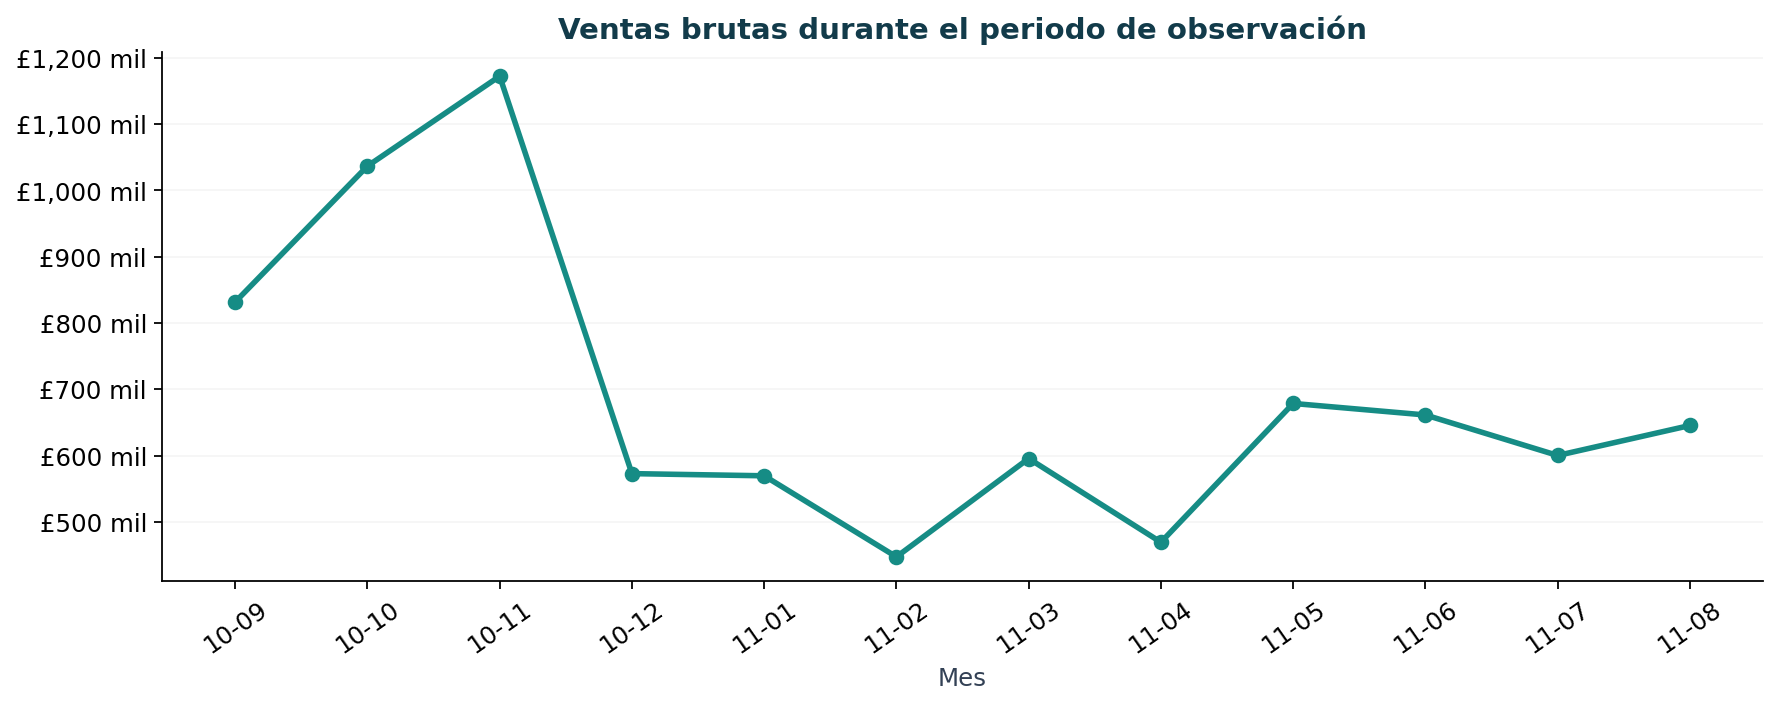

In [3]:
display(monthly.round(2))
display(Image(filename=str(REPORTS / "figures/monthly_sales.png")))

## Concentración del gasto
Se ordenan los clientes por gasto bruto. La proporción acumulada permite comparar el peso de
la cartera con su contribución comercial. No atribuye rentabilidad: faltan costos.

Los 433 clientes de mayor gasto aportan 60.3%.


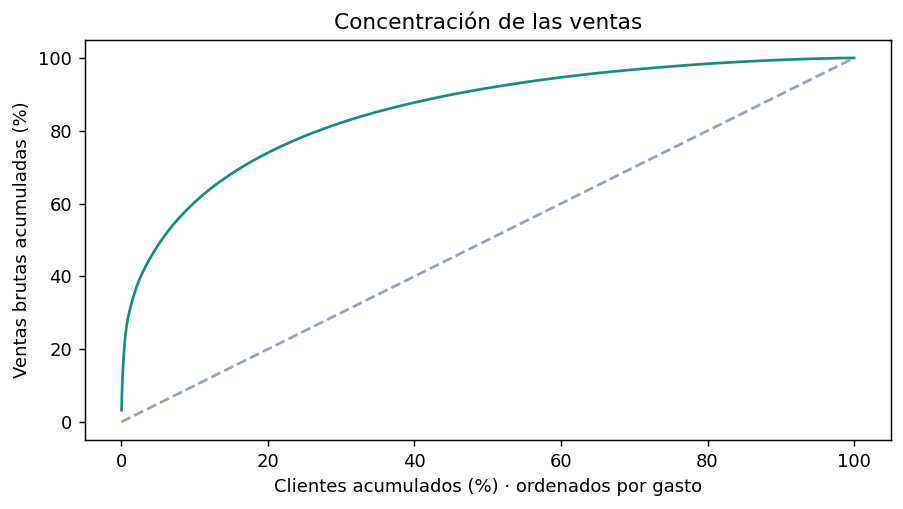

In [4]:
import io

import matplotlib.pyplot as plt

ranked = rfm.sort_values("monetary", ascending=False).reset_index(drop=True)
ranked["customer_share"] = (np.arange(len(ranked)) + 1) / len(ranked)
ranked["revenue_share"] = ranked.monetary.cumsum() / ranked.monetary.sum()
top_n = int(len(ranked) * 0.10)
print(f"Los {top_n} clientes de mayor gasto aportan {ranked.iloc[top_n - 1].revenue_share:.1%}.")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ranked.customer_share * 100, ranked.revenue_share * 100, color="#168C85")
ax.plot([0, 100], [0, 100], linestyle="--", color="#94A3B8")
ax.set(
    xlabel="Clientes acumulados (%) · ordenados por gasto",
    ylabel="Ventas brutas acumuladas (%)",
    title="Concentración de las ventas",
)

buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
display(Image(data=buffer.getvalue()))
plt.close(fig)

In [5]:
repeat = rfm.frequency.gt(1)
display(
    pd.DataFrame(
        {
            "Comportamiento": ["Un pedido", "Más de un pedido"],
            "Clientes": [(~repeat).sum(), repeat.sum()],
            "Participación": [(~repeat).mean(), repeat.mean()],
        }
    )
)
display(
    rfm.groupby("country")
    .agg(clientes=("customer_id", "size"), gasto_bruto=("monetary", "sum"))
    .sort_values("gasto_bruto", ascending=False)
    .head(10)
)

,Comportamiento,Clientes,Participación
0,Un pedido,1574,0.363091
1,Más de un pedido,2761,0.636909


,clientes,gasto_bruto
country,,
United Kingdom,3947,6778267.495
Netherlands,14,278560.130
EIRE,3,271776.880
Germany,77,212573.580
France,71,162576.540
Australia,12,131213.430
Spain,27,64043.250
Switzerland,20,57528.300
Sweden,12,39279.610


## Hallazgo comercial
El 10 % superior concentra aproximadamente el 60,3 % del gasto y el 63,7 % de los clientes tiene
más de un pedido. Esto justifica estudiar comportamientos diferentes. La presencia de mayoristas
es una razón para interpretar con cuidado a los clientes de gasto elevado.

[Continuar: indicadores por cliente](03_rfm_features.ipynb)